# Feature creation with Feature-engine

This notebook puts mathematical and relative feature creation inside a scikit-learn pipeline. It uses the current Feature-engine MathFeatures and RelativeFeatures transformers and then fits a gradient-boosting regression model.

## Why put creation inside a pipeline?

A manually created column can be forgotten during prediction or calculated differently in production. A pipeline stores the formulas and applies them in the same order to training, validation, test, and future records. It also makes cross-validation safer.

In [1]:
import importlib.util,subprocess,sys
required={'numpy':'numpy','pandas':'pandas','matplotlib':'matplotlib','seaborn':'seaborn','sklearn':'scikit-learn','feature_engine':'feature-engine'}
missing=[package for module,package in required.items() if importlib.util.find_spec(module) is None]
if missing: subprocess.check_call([sys.executable,'-m','pip','install',*missing])
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from feature_engine.creation import MathFeatures,RelativeFeatures
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
sns.set_theme(style='whitegrid',context='notebook')

## 1. Load the Ames data

We use a small set of numerical columns whose names describe meaningful house measurements. The target SalePrice is kept separate from X.

In [2]:
candidates=[Path('feature-engineering/imputation/houseprice.csv'),Path('../imputation/houseprice.csv'),Path('houseprice.csv')]
path=next((p for p in candidates if p.exists()),None)
if path is None: raise FileNotFoundError('Place houseprice.csv in feature-engineering/imputation/.')
data=pd.read_csv(path,na_values=['NA'])
features=['GrLivArea','TotalBsmtSF','LotArea','BsmtFinSF1','BsmtUnfSF','GarageArea','OverallQual']
model_data=data[features+['SalePrice']].dropna().copy()
X=model_data[features]; y=model_data['SalePrice']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.20,random_state=42)
print('Train:',X_train.shape,'Test:',X_test.shape)

Train: (1168, 7) Test: (292, 7)


## 2. Define the creation pipeline

The pipeline creates total and average area, an unfinished-basement gap, living-area utilisation, and basement proportion. The original columns remain available to the model because a new feature should add information rather than silently replace useful measurements.

In [3]:
feature_pipeline=Pipeline([
    ('area_math',MathFeatures(variables=['GrLivArea','TotalBsmtSF'],func=['sum','mean'],new_variables_names=['total_main_and_basement_area','average_main_and_basement_area'])),
    ('basement_math',MathFeatures(variables=['BsmtFinSF1','BsmtUnfSF'],func=['sum'],new_variables_names=['basement_area_check'])),
    ('living_to_lot',RelativeFeatures(variables=['GrLivArea'],reference=['LotArea'],func=['div'],fill_value=0,missing_values='ignore')),
    ('finished_to_total_basement',RelativeFeatures(variables=['BsmtFinSF1'],reference=['TotalBsmtSF'],func=['div'],fill_value=0,missing_values='ignore')),
    ('model',GradientBoostingRegressor(n_estimators=150,max_depth=2,learning_rate=.04,random_state=42))
])
feature_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('area_math', ...), ('basement_math', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,variables,"['GrLivArea', 'TotalBsmtSF']"
,func,"['sum', 'mean']"
,new_variables_names,"['total_main_and_basement_area', 'average_main_and_basement_area']"
,missing_values,'raise'
,drop_original,False
,variables,"['BsmtFinSF1', 'BsmtUnfSF']"
,func,['sum']


## 3. Fit and evaluate

MAE is the average absolute price error, RMSE penalises large mistakes, and R² measures explained variation. Compare these metrics with a baseline that uses the raw columns only before claiming that creation helped.

In [4]:
feature_pipeline.fit(X_train,y_train)
train_pred=feature_pipeline.predict(X_train)
test_pred=feature_pipeline.predict(X_test)
metrics=pd.DataFrame({'Train':{'MAE':mean_absolute_error(y_train,train_pred),'RMSE':np.sqrt(mean_squared_error(y_train,train_pred)),'R2':r2_score(y_train,train_pred)},'Test':{'MAE':mean_absolute_error(y_test,test_pred),'RMSE':np.sqrt(mean_squared_error(y_test,test_pred)),'R2':r2_score(y_test,test_pred)}}).T
display(metrics.round(2))

,MAE,RMSE,R2
Train,18103.93,25476.54,0.89
Test,21557.52,33514.65,0.85


## 4. Inspect created columns and importance

Feature-engine transformers retain a pandas DataFrame, which makes it possible to see the generated names. Importance is a model-specific signal, not proof of causality.

Created columns: ['total_main_and_basement_area', 'average_main_and_basement_area', 'basement_area_check', 'GrLivArea_div_LotArea', 'BsmtFinSF1_div_TotalBsmtSF']


,total_main_and_basement_area,average_main_and_basement_area,basement_area_check,GrLivArea_div_LotArea,BsmtFinSF1_div_TotalBsmtSF
254,2628.0,1314.0,1314,0.156429,0.701674
1066,2370.0,1185.0,799,0.200459,0.000000
638,1592.0,796.0,796,0.090692,0.000000
799,2499.0,1249.5,731,0.245556,0.778386
380,2717.0,1358.5,1026,0.338200,0.212476


,importance
OverallQual,0.464196
average_main_and_basement_area,0.209763
total_main_and_basement_area,0.194747
BsmtFinSF1,0.036654
GarageArea,0.034959
GrLivArea,0.024933
LotArea,0.017667
GrLivArea_div_LotArea,0.011058
BsmtFinSF1_div_TotalBsmtSF,0.002338
basement_area_check,0.001512


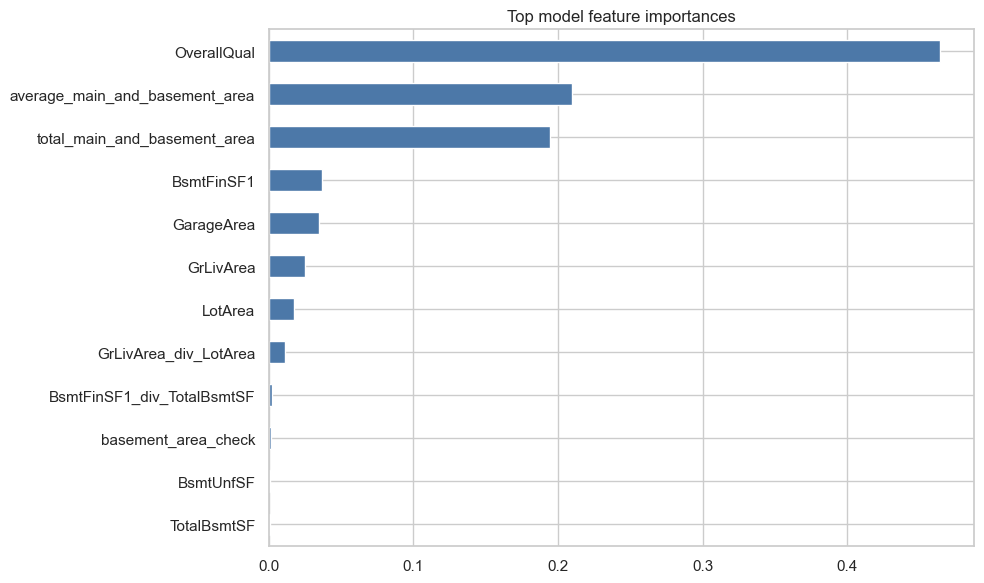

In [5]:
created_train=feature_pipeline[:-1].transform(X_train)
new_columns=[column for column in created_train.columns if column not in X_train.columns]
print('Created columns:',new_columns)
display(created_train[new_columns].head())
importance=pd.Series(feature_pipeline.named_steps['model'].feature_importances_,index=created_train.columns).sort_values(ascending=False).head(15)
display(importance.to_frame('importance'))
plt.figure(figsize=(10,6)); importance.sort_values().plot.barh(color='#4C78A8'); plt.title('Top model feature importances'); plt.tight_layout(); plt.show()

## Practical checks

- Protect division by zero with a documented fallback and, when useful, an indicator.
- Keep units and business meaning clear.
- Do not create features from information unavailable at prediction time.
- Fit learned transformations inside the pipeline and cross-validation.
- Compare the engineered pipeline with a raw-feature baseline.
- Monitor distributions after deployment because ratios and products can drift.

## Summary

Feature-engine turns feature formulas into reusable transformers. Combining MathFeatures and RelativeFeatures with a model pipeline makes feature creation reproducible, inspectable, and safer to evaluate.